# Entrenamiento de XGBoost Multicanal

**Maestría en Inteligencia Artificial MAIA**

**Proyecto - Desarrollo de Soluciones**

***Estudiantes:***
- María José García (mj.garciab1@uniandes.edu.co)
- Daniel Osuna (d.osuna@uniandes.edu.co)
- Gabriel Vizcaya (g.vizcaya@uniandes.edu.co)
- Joel Vargas (js.vargasl1@uniandes.edu.co)

Entrenamiento supervisado con `XGBClassifier` usando `train_multicanal.csv` y `test_multicanal.csv`. El dataset multicanal conserva un único esquema de columnas para soportar inferencia cuando `EEG Fpz-Cz` está presente y `EEG Pz-Oz` / `EOG horizontal` son opcionales. La evaluación se reporta de forma global y por combinación de canales (`channel_combo`).

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    classification_report,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))
from src.data.segmentation import CLASS_NAMES, INT_TO_CLASS

try:
    from xgboost import XGBClassifier
except Exception as exc:
    raise ImportError(
        "No se pudo importar XGBoost. En macOS suele faltar el runtime OpenMP; "
        "instalalo con `brew install libomp` y vuelve a ejecutar el kernel."
    ) from exc

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

## Configuración

El entrenamiento excluye identificadores y columnas de control que pueden generar fuga de información (`recording_id`, `subject_code`, `split`, `epoch_idx_in_recording`). Sí se conservan las columnas de disponibilidad de canales (`has_eeg_pz_oz`, `has_eog_horizontal`), `channel_count` y una codificación one-hot de `channel_combo`, porque esas variables representan qué señales están disponibles en inferencia.

In [6]:
RANDOM_STATE = 42
CV_SPLITS = 5
N_ITER_SEARCH = 10
SCORING = "f1_macro"

TARGET_COLUMN = "y"
ID_COLUMNS = ["recording_id", "subject_code"]
CONTROL_COLUMNS = ["split", "epoch_idx_in_recording"]
CATEGORICAL_COLUMNS = ["channel_combo"]

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data" / "processed" / "train_multicanal.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

TRAIN_PATH = DATA_DIR / "train_multicanal.csv"
TEST_PATH = DATA_DIR / "test_multicanal.csv"

MODEL_PATH = MODEL_DIR / "best-xgboost-multicanal-model.json"
JOBLIB_PATH = MODEL_DIR / "best-xgboost-multicanal.joblib"
INFO_PATH = MODEL_DIR / "model_info_multicanal.json"
METRICS_BY_COMBO_PATH = MODEL_DIR / "metrics_by_channel_combo_multicanal.csv"
PER_CLASS_BY_COMBO_PATH = MODEL_DIR / "per_class_metrics_by_channel_combo_multicanal.csv"
FEATURE_IMPORTANCE_PATH = MODEL_DIR / "feature_importance_multicanal.csv"

TRAIN_PATH, TEST_PATH, MODEL_DIR

(PosixPath('/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/data/processed/train_multicanal.csv'),
 PosixPath('/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/data/processed/test_multicanal.csv'),
 PosixPath('/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/models'))

## Carga de datos

In [3]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print(f"Train shape: {train_df.shape}")
print(f"Test shape:  {test_df.shape}")

display(train_df.head())
display(train_df[TARGET_COLUMN].value_counts().sort_index().rename("train_count"))
display(test_df[TARGET_COLUMN].value_counts().sort_index().rename("test_count"))
display(train_df["channel_combo"].value_counts().rename("train_rows_by_combo"))
display(test_df["channel_combo"].value_counts().rename("test_rows_by_combo"))

Train shape: (601088, 51)
Test shape:  (180828, 51)


,channel_combo,channel_count,split,epoch_idx_in_recording,has_eeg_pz_oz,has_eog_horizontal,recording_id,subject_code,y,EEG_Fpz-Cz__alpha_power_abs,...,EOG_horizontal__delta_alpha_ratio,EOG_horizontal__delta_power_abs,EOG_horizontal__delta_power_rel,EOG_horizontal__sef95,EOG_horizontal__sigma_power_abs,EOG_horizontal__sigma_power_rel,EOG_horizontal__spectral_entropy,EOG_horizontal__theta_alpha_ratio,EOG_horizontal__theta_power_abs,EOG_horizontal__theta_power_rel
0,eeg_fpz_cz,1,train,0,False,False,SC4001E0,0,W,5.486738,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,eeg_fpz_cz,1,train,1,False,False,SC4001E0,0,W,4.664630,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,eeg_fpz_cz,1,train,2,False,False,SC4001E0,0,W,5.123155,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,eeg_fpz_cz,1,train,3,False,False,SC4001E0,0,W,6.026664,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,eeg_fpz_cz,1,train,4,False,False,SC4001E0,0,W,5.224161,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


y
N1      65780
N2     214372
N3      42316
REM     80360
W      198260
Name: train_count, dtype: int64

y
N1     20308
N2     62156
N3      9840
REM    22980
W      65544
Name: test_count, dtype: int64

channel_combo
eeg_fpz_cz                               150272
eeg_fpz_cz__eeg_pz_oz                    150272
eeg_fpz_cz__eog_horizontal               150272
eeg_fpz_cz__eeg_pz_oz__eog_horizontal    150272
Name: train_rows_by_combo, dtype: int64

channel_combo
eeg_fpz_cz                               45207
eeg_fpz_cz__eeg_pz_oz                    45207
eeg_fpz_cz__eog_horizontal               45207
eeg_fpz_cz__eeg_pz_oz__eog_horizontal    45207
Name: test_rows_by_combo, dtype: int64

## Preparación de matrices

In [4]:
missing_columns = set(train_df.columns) ^ set(test_df.columns)
if missing_columns:
    raise ValueError(f"Train y test no tienen las mismas columnas: {missing_columns}")

excluded_columns = [TARGET_COLUMN, *ID_COLUMNS, *CONTROL_COLUMNS]
base_feature_columns = [column for column in train_df.columns if column not in excluded_columns]

X_train_raw = train_df[base_feature_columns].copy()
X_test_raw = test_df[base_feature_columns].copy()

# Codificación explícita de la combinación de canales. Esto permite que el modelo
# aprenda calibraciones distintas según disponibilidad de señales, manteniendo un
# único esquema de inferencia.
X_train = pd.get_dummies(X_train_raw, columns=CATEGORICAL_COLUMNS, dtype=np.int8)
X_test = pd.get_dummies(X_test_raw, columns=CATEGORICAL_COLUMNS, dtype=np.int8)
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

# Booleans a enteros para evitar problemas de serialización/tipos.
for df in (X_train, X_test):
    bool_columns = df.select_dtypes(include="bool").columns
    df[bool_columns] = df[bool_columns].astype(np.int8)

feature_columns = X_train.columns.tolist()

# Los datos nuevos tienen y como nombres de clase. El map mantiene compatibilidad
# con CSV antiguos donde y estaba guardada como 0, 1, 2, 3, 4.
y_train_names = train_df[TARGET_COLUMN].map(INT_TO_CLASS).fillna(train_df[TARGET_COLUMN]).astype(str)
y_test_names = test_df[TARGET_COLUMN].map(INT_TO_CLASS).fillna(test_df[TARGET_COLUMN]).astype(str)

label_encoder = LabelEncoder()
label_encoder.fit(CLASS_NAMES)
y_train = label_encoder.transform(y_train_names)
y_test = label_encoder.transform(y_test_names)
class_labels = np.array(CLASS_NAMES)

groups = train_df["subject_code"].astype(str).to_numpy()
sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

print(f"Número de features: {len(feature_columns)}")
print(f"Clases: {class_labels.tolist()}")
print(f"Número de pacientes/grupos en train: {pd.Series(groups).nunique()}")
print(f"Columnas excluidas: {excluded_columns}")
display(pd.Series(feature_columns, name="features"))

Número de features: 49
Clases: ['W', 'N1', 'N2', 'N3', 'REM']
Número de pacientes/grupos en train: 62
Columnas excluidas: ['y', 'recording_id', 'subject_code', 'split', 'epoch_idx_in_recording']


0                                         channel_count
1                                         has_eeg_pz_oz
2                                    has_eog_horizontal
3                           EEG_Fpz-Cz__alpha_power_abs
4                           EEG_Fpz-Cz__alpha_power_rel
5                            EEG_Fpz-Cz__beta_power_abs
6                            EEG_Fpz-Cz__beta_power_rel
7                         EEG_Fpz-Cz__delta_alpha_ratio
8                           EEG_Fpz-Cz__delta_power_abs
9                           EEG_Fpz-Cz__delta_power_rel
10                                    EEG_Fpz-Cz__sef95
11                          EEG_Fpz-Cz__sigma_power_abs
12                          EEG_Fpz-Cz__sigma_power_rel
13                         EEG_Fpz-Cz__spectral_entropy
14                        EEG_Fpz-Cz__theta_alpha_ratio
15                          EEG_Fpz-Cz__theta_power_abs
16                          EEG_Fpz-Cz__theta_power_rel
17                           EEG_Pz-Oz__alpha_po

## Búsqueda de hiperparámetros con validación cruzada

La búsqueda usa `RandomizedSearchCV` con CV estratificada por clase y agrupada por `subject_code`. Así, todas las épocas de un mismo paciente quedan completas en train o validation dentro de cada fold. El mejor modelo se selecciona por `f1_macro`.

In [7]:
base_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(class_labels),
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

param_distributions = {
    "n_estimators": [200, 300, 500, 700],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "gamma": [0, 0.1, 0.3, 0.5, 1.0],
    "reg_alpha": [0, 0.01, 0.1, 0.5],
    "reg_lambda": [0.5, 1.0, 1.5, 2.0],
}

cv = StratifiedGroupKFold(
    n_splits=CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_distributions,
    n_iter=N_ITER_SEARCH,
    scoring=SCORING,
    cv=cv,
    verbose=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
)
search.fit(X_train, y_train, groups=groups, sample_weight=sample_weights)
best_model = search.best_estimator_
best_cv_score = search.best_score_
best_params = search.best_params_


print(f"Mejor {SCORING} CV: {best_cv_score}")
print("Mejores hiperparámetros:")
display(best_params)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END gamma=1.0, learning_rate=0.05, max_depth=6, n_estimators=500, reg_alpha=0.01, reg_lambda=1.5; total time= 2.6min
[CV] END gamma=1.0, learning_rate=0.05, max_depth=6, n_estimators=500, reg_alpha=0.01, reg_lambda=1.5; total time= 2.6min
[CV] END gamma=1.0, learning_rate=0.05, max_depth=6, n_estimators=500, reg_alpha=0.01, reg_lambda=1.5; total time= 2.6min
[CV] END gamma=1.0, learning_rate=0.05, max_depth=6, n_estimators=500, reg_alpha=0.01, reg_lambda=1.5; total time= 2.6min
[CV] END gamma=1.0, learning_rate=0.05, max_depth=6, n_estimators=500, reg_alpha=0.01, reg_lambda=1.5; total time= 2.6min
[CV] END gamma=1.0, learning_rate=0.08, max_depth=6, n_estimators=700, reg_alpha=0, reg_lambda=2.0; total time= 3.3min
[CV] END gamma=1.0, learning_rate=0.08, max_depth=6, n_estimators=700, reg_alpha=0, reg_lambda=2.0; total time= 3.3min
[CV] END gamma=1.0, learning_rate=0.08, max_depth=6, n_estimators=700, reg_alpha=0, reg_lam

{'reg_lambda': 0.5,
 'reg_alpha': 0.5,
 'n_estimators': 700,
 'max_depth': 6,
 'learning_rate': 0.03,
 'gamma': 0.3}

In [8]:
cv_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
cv_summary_columns = [
    "rank_test_score",
    "mean_test_score",
    "std_test_score",
    "mean_train_score",
    "std_train_score",
    "params",
]
display(cv_results[cv_summary_columns].head(10))

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
6,1,0.702063,0.019186,0.811299,0.003008,"{'reg_lambda': 0.5, 'reg_alpha': 0.5, 'n_estim..."
2,2,0.701684,0.019012,0.796073,0.003044,"{'reg_lambda': 0.5, 'reg_alpha': 0.5, 'n_estim..."
0,3,0.700966,0.019159,0.819845,0.002715,"{'reg_lambda': 1.5, 'reg_alpha': 0.01, 'n_esti..."
7,4,0.699278,0.019319,0.830711,0.002837,"{'reg_lambda': 0.5, 'reg_alpha': 0.01, 'n_esti..."
4,5,0.698717,0.019033,0.755543,0.003650,"{'reg_lambda': 1.5, 'reg_alpha': 0.1, 'n_estim..."
3,6,0.697812,0.019648,0.799527,0.003202,"{'reg_lambda': 1.5, 'reg_alpha': 0.5, 'n_estim..."
9,7,0.696475,0.020299,0.846058,0.002171,"{'reg_lambda': 1.0, 'reg_alpha': 0.1, 'n_estim..."
1,8,0.694654,0.020528,0.862958,0.002121,"{'reg_lambda': 2.0, 'reg_alpha': 0, 'n_estimat..."
8,9,0.693460,0.021650,0.880652,0.002586,"{'reg_lambda': 1.5, 'reg_alpha': 0.01, 'n_esti..."
5,10,0.680792,0.019965,0.722692,0.004199,"{'reg_lambda': 2.0, 'reg_alpha': 0.01, 'n_esti..."


## Evaluación global en test

In [9]:
y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
kappa = cohen_kappa_score(y_test, y_pred)

precision, recall, f1, support = precision_recall_fscore_support(
    y_test,
    y_pred,
    labels=label_encoder.transform(class_labels),
    zero_division=0,
)

metrics = {
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "balanced_accuracy": balanced_acc,
    "cohens_kappa": kappa,
    "best_cv_macro_f1": best_cv_score,
    "best_params": best_params,
}

per_class_metrics = pd.DataFrame(
    {
        "class": class_labels,
        "precision_per_class": precision,
        "recall_per_class": recall,
        "f1_per_class": f1,
        "support": support,
    }
)

display(pd.Series(metrics, name="value"))
display(per_class_metrics)
print(classification_report(y_test, y_pred, target_names=[str(label) for label in class_labels], zero_division=0))

accuracy                                                      0.727841
macro_f1                                                      0.671259
balanced_accuracy                                             0.713934
cohens_kappa                                                  0.633434
best_cv_macro_f1                                              0.702063
best_params          {'reg_lambda': 0.5, 'reg_alpha': 0.5, 'n_estim...
Name: value, dtype: object

,class,precision_per_class,recall_per_class,f1_per_class,support
0,W,0.881665,0.847888,0.864447,65544
1,N1,0.338121,0.485671,0.398682,20308
2,N2,0.895705,0.684504,0.775990,62156
3,N3,0.591928,0.915142,0.718876,9840
4,REM,0.564449,0.636466,0.598298,22980


              precision    recall  f1-score   support

           W       0.34      0.49      0.40     20308
          N1       0.90      0.68      0.78     62156
          N2       0.59      0.92      0.72      9840
          N3       0.56      0.64      0.60     22980
         REM       0.88      0.85      0.86     65544

    accuracy                           0.73    180828
   macro avg       0.65      0.71      0.67    180828
weighted avg       0.77      0.73      0.74    180828



## Métricas por combinación de canales

,channel_combo,support,accuracy,macro_f1,balanced_accuracy,cohens_kappa
1,eeg_fpz_cz,45207,0.675603,0.618189,0.664653,0.565943
2,eeg_fpz_cz__eeg_pz_oz,45207,0.734267,0.673863,0.713356,0.641744
3,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,45207,0.763864,0.710201,0.748709,0.680304
4,eeg_fpz_cz__eog_horizontal,45207,0.737629,0.684727,0.729019,0.646445
0,overall,180828,0.727841,0.671259,0.713934,0.633434


,channel_combo,class,precision_per_class,recall_per_class,f1_per_class,support
1,eeg_fpz_cz,N1,0.297022,0.424266,0.349420,5077
2,eeg_fpz_cz,N2,0.894803,0.642641,0.748043,15539
3,eeg_fpz_cz,N3,0.554867,0.910569,0.689549,2460
4,eeg_fpz_cz,REM,0.440810,0.553525,0.490779,5745
0,eeg_fpz_cz,W,0.835178,0.792262,0.813154,16386
6,eeg_fpz_cz__eeg_pz_oz,N1,0.329906,0.493008,0.395294,5077
7,eeg_fpz_cz__eeg_pz_oz,N2,0.899070,0.684471,0.777230,15539
8,eeg_fpz_cz__eeg_pz_oz,N3,0.609472,0.915447,0.731763,2460
9,eeg_fpz_cz__eeg_pz_oz,REM,0.555160,0.596519,0.575096,5745
5,eeg_fpz_cz__eeg_pz_oz,W,0.902902,0.877334,0.889934,16386


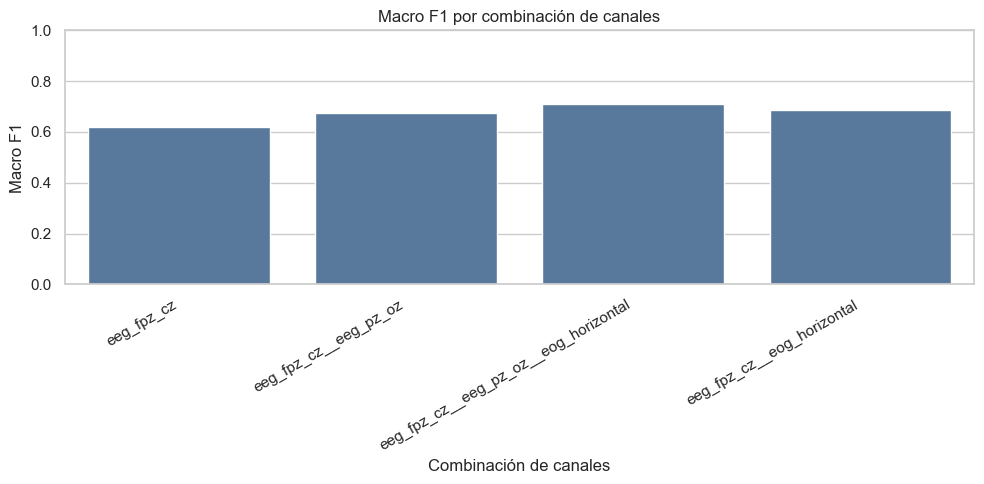

In [10]:
def evaluate_predictions(y_true, y_hat, labels, prefix=None):
    return {
        "channel_combo": prefix,
        "support": int(len(y_true)),
        "accuracy": accuracy_score(y_true, y_hat),
        "macro_f1": f1_score(y_true, y_hat, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_hat),
        "cohens_kappa": cohen_kappa_score(y_true, y_hat),
    }

combo_metric_rows = []
combo_per_class_rows = []

test_eval_df = test_df[["channel_combo", "recording_id", "subject_code", TARGET_COLUMN]].copy()
test_eval_df["y_true"] = y_test
test_eval_df["y_pred"] = y_pred

overall_row = evaluate_predictions(y_test, y_pred, label_encoder.transform(class_labels), prefix="overall")
combo_metric_rows.append(overall_row)

for combo_name, combo_df in test_eval_df.groupby("channel_combo", sort=True):
    combo_y_true = combo_df["y_true"].to_numpy()
    combo_y_pred = combo_df["y_pred"].to_numpy()
    combo_metric_rows.append(evaluate_predictions(combo_y_true, combo_y_pred, label_encoder.transform(class_labels), prefix=combo_name))

    p, r, f, s = precision_recall_fscore_support(
        combo_y_true,
        combo_y_pred,
        labels=label_encoder.transform(class_labels),
        zero_division=0,
    )
    for class_name, precision_i, recall_i, f1_i, support_i in zip(class_labels, p, r, f, s):
        combo_per_class_rows.append(
            {
                "channel_combo": combo_name,
                "class": class_name,
                "precision_per_class": precision_i,
                "recall_per_class": recall_i,
                "f1_per_class": f1_i,
                "support": support_i,
            }
        )

metrics_by_combo = pd.DataFrame(combo_metric_rows).sort_values("channel_combo")
per_class_by_combo = pd.DataFrame(combo_per_class_rows).sort_values(["channel_combo", "class"])

display(metrics_by_combo)
display(per_class_by_combo)

plt.figure(figsize=(10, 5))
sns.barplot(data=metrics_by_combo[metrics_by_combo["channel_combo"] != "overall"], x="channel_combo", y="macro_f1", color="#4C78A8")
plt.title("Macro F1 por combinación de canales")
plt.xlabel("Combinación de canales")
plt.ylabel("Macro F1")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.tight_layout()

## Matriz de confusión global y por combinación

,W,N1,N2,N3,REM
W,55574,6689,344,396,2541
N1,4006,9863,2686,120,3633
N2,1802,7104,42546,5595,5109
N3,154,22,656,9005,3
REM,1497,5492,1268,97,14626


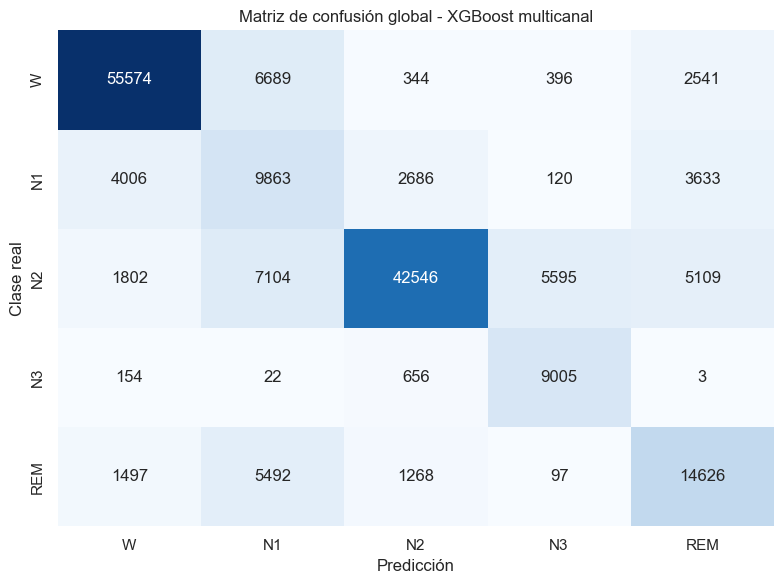

In [11]:
conf_matrix = confusion_matrix(y_test, y_pred, labels=label_encoder.transform(class_labels))
conf_matrix_df = pd.DataFrame(conf_matrix, index=class_labels, columns=class_labels)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_df, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Matriz de confusión global - XGBoost multicanal")
plt.xlabel("Predicción")
plt.ylabel("Clase real")
plt.tight_layout()

display(conf_matrix_df)

,W,N1,N2,N3,REM
W,12982,2001,158,228,1017
N1,1162,2154,562,43,1156
N2,705,1491,9986,1496,1861
N3,68,2,150,2240,0
REM,627,1604,304,30,3180


,W,N1,N2,N3,REM
W,14376,1463,45,54,448
N1,896,2503,682,27,969
N2,338,1900,10636,1337,1328
N3,17,7,183,2252,1
REM,295,1714,284,25,3427


,W,N1,N2,N3,REM
W,14451,1464,51,46,374
N1,929,2665,750,18,715
N2,303,1958,11119,1314,845
N3,16,9,176,2259,0
REM,249,1123,317,18,4038


,W,N1,N2,N3,REM
W,13765,1761,90,68,702
N1,1019,2541,692,32,793
N2,456,1755,10805,1448,1075
N3,53,4,147,2254,2
REM,326,1051,363,24,3981


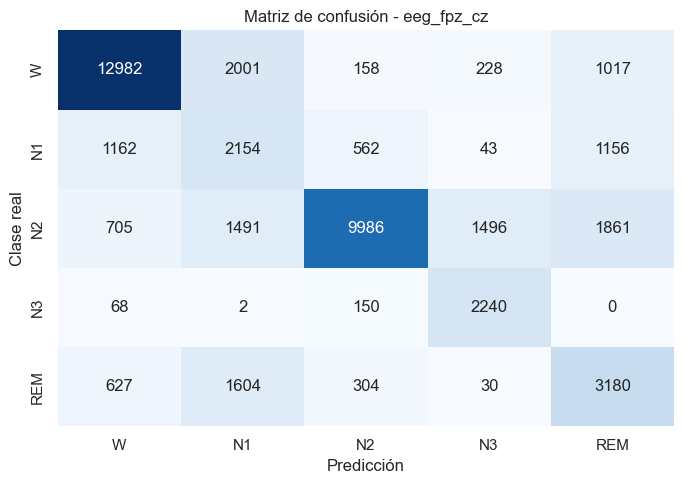

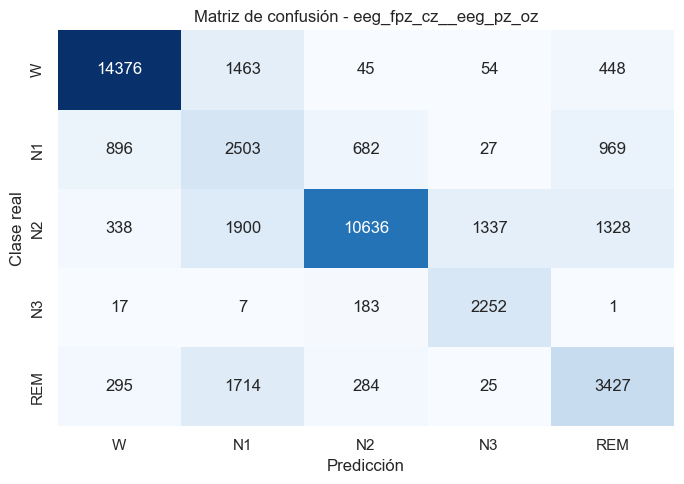

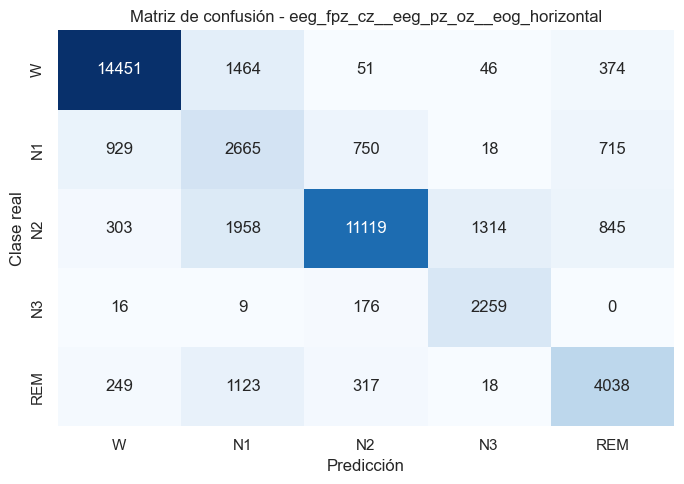

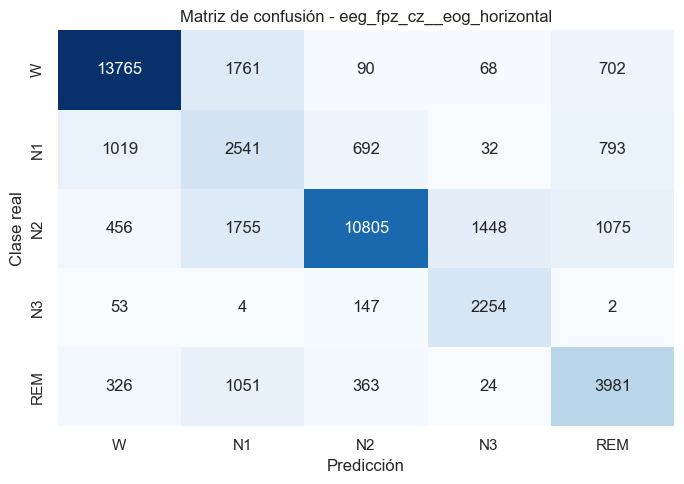

In [12]:
for combo_name, combo_df in test_eval_df.groupby("channel_combo", sort=True):
    combo_conf_matrix = confusion_matrix(
        combo_df["y_true"],
        combo_df["y_pred"],
        labels=label_encoder.transform(class_labels),
    )
    combo_conf_matrix_df = pd.DataFrame(combo_conf_matrix, index=class_labels, columns=class_labels)
    plt.figure(figsize=(7, 5))
    sns.heatmap(combo_conf_matrix_df, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(f"Matriz de confusión - {combo_name}")
    plt.xlabel("Predicción")
    plt.ylabel("Clase real")
    plt.tight_layout()
    display(combo_conf_matrix_df)

## Importancia de variables

,feature,importance
48,channel_combo_eeg_fpz_cz__eog_horizontal,0.130774
8,EEG_Fpz-Cz__delta_power_abs,0.099389
0,channel_count,0.092415
6,EEG_Fpz-Cz__beta_power_rel,0.069255
35,EOG_horizontal__delta_alpha_ratio,0.050987
33,EOG_horizontal__beta_power_abs,0.041208
36,EOG_horizontal__delta_power_abs,0.039488
20,EEG_Pz-Oz__beta_power_rel,0.035563
5,EEG_Fpz-Cz__beta_power_abs,0.034252
18,EEG_Pz-Oz__alpha_power_rel,0.026345


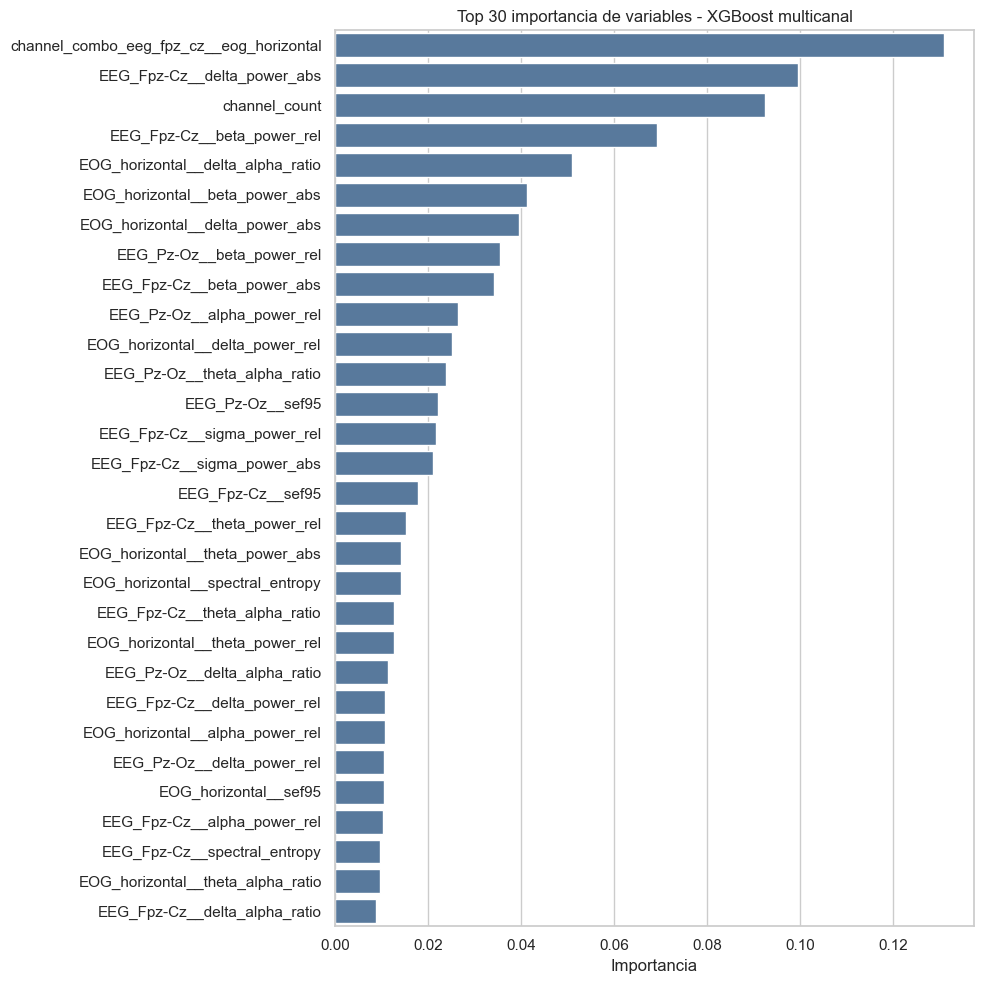

In [13]:
feature_importance = pd.DataFrame(
    {
        "feature": feature_columns,
        "importance": best_model.feature_importances_,
    }
).sort_values("importance", ascending=False)

plt.figure(figsize=(10, 10))
sns.barplot(data=feature_importance.head(30), x="importance", y="feature", color="#4C78A8")
plt.title("Top 30 importancia de variables - XGBoost multicanal")
plt.xlabel("Importancia")
plt.ylabel("")
plt.tight_layout()

display(feature_importance)

## Guardado de artefactos

In [14]:
best_model.save_model(MODEL_PATH)
joblib.dump(
    {
        "model": best_model,
        "label_encoder": label_encoder,
        "feature_columns": feature_columns,
        "excluded_columns": excluded_columns,
        "categorical_columns": CATEGORICAL_COLUMNS,
        "class_labels": class_labels.tolist(),
    },
    JOBLIB_PATH,
)

feature_importance.to_csv(FEATURE_IMPORTANCE_PATH, index=False)
metrics_by_combo.to_csv(METRICS_BY_COMBO_PATH, index=False)
per_class_by_combo.to_csv(PER_CLASS_BY_COMBO_PATH, index=False)

info = {
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "balanced_accuracy": balanced_acc,
    "cohens_kappa": kappa,
    "best_cv_macro_f1": best_cv_score,
    "best_params": best_params,
    "feature_columns": feature_columns,
    "excluded_columns": excluded_columns,
    "metrics_by_channel_combo": metrics_by_combo.to_dict(orient="records"),
}

with open(INFO_PATH, "w") as f:
    json.dump(info, f, indent=4)

print(f"Modelo XGBoost guardado en: {MODEL_PATH}")
print(f"Pipeline joblib guardado en: {JOBLIB_PATH}")
print(f"Info guardada en: {INFO_PATH}")
print(f"Métricas por combinación guardadas en: {METRICS_BY_COMBO_PATH}")

Modelo XGBoost guardado en: /Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/models/best-xgboost-multicanal-model.json
Pipeline joblib guardado en: /Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/models/best-xgboost-multicanal.joblib
Info guardada en: /Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/models/model_info_multicanal.json
Métricas por combinación guardadas en: /Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/models/metrics_by_channel_combo_multicanal.csv
